# Homework 6 -- ATOC 4815/5815

**Due: 10/15, 11:59 pm.** Submit via Canvas ("HW6") as an `.ipynb` file.

**This is the last homework you will submit via Canvas.** Starting with HW7, assignments
will be distributed *and* submitted through the class GitHub repository instead.

This homework is a partially-completed notebook rather than a PDF: some cells are
already filled in for you (things we covered in class, or that set up the problem),
and some are marked **`# TODO`** -- those are the parts you need to write.

**Skills practiced:**
- Gridding non-rectilinear (scattered) satellite data onto a regular geographic grid
- Working with multi-day weather station data: climatology (daily mean/min/max over a period)
- Taylor series expansion with `numpy` / `scipy`/ a `for` loop


## Context: a real bug, and the code this homework builds on

On 10/6, running `modis_terrain.py` live in class in the new `atoc4815` environment
threw a real error: `AttributeError: QuadContourSet.set() got an unexpected keyword
argument 'projection'`. That line had actually been using the wrong keyword all along
(`projection=` instead of `transform=` on `ax.contour(...)`) -- it just happened to run
without complaint in the old class environment, because older matplotlib silently
ignored keyword arguments it didn't recognize instead of raising an error. Newer
matplotlib is stricter, and it caught a bug that had been sitting there the whole time.
**"It ran before" is not the same as "it was correct before."**

Two files came out of fixing and explaining that, and they're the starting point for
Task 1 below:

- **`modis_terrain_corrected.py`** -- the bug-fixed version of the MODIS code, heavily
  commented to explain what was wrong, why it only failed now, and what each of its two
  plots is for.
- **`grid_regular_annotated.py`** -- an annotated version of the gridding demo code from
  class, walking through the boundaries-vs-midpoints setup and the nearest-index lookup
  you'll need for Task 1.

Both are posted on Canvas alongside this notebook, and are also in the class GitHub
repository's `code/` folder -- if you already cloned `ATOC-4815` for the environment
setup, run `git pull` inside that folder to get them.

### Where to put this notebook

This notebook imports from `weather.py` and reads a file from a `dat/` folder, so its
location relative to those matters:

1. Save this file as `hw6.ipynb` **inside the `code/` folder of your cloned `ATOC-4815`
   repository** -- the same folder `weather.py` is already in. (Not your Desktop, not
   the top-level `ATOC-4815` folder -- it has to sit right next to `weather.py` for
   `from weather import ...` to work.)
2. Download the MOD03 file from the HW6 page on Canvas, and put it in a folder named
   `dat/` that sits next to `code/` (i.e. one level up from this notebook) -- the same
   layout the class `py/` and `dat/` folders use. Data files aren't part of the GitHub
   repo, so this is a separate download.

If both of those are in place, the folder structure looks like:
```
ATOC-4815/
├── dat/
│   └── MOD03.A2017233.1745.006.2017234003402.hdf
└── code/
    ├── weather.py
    └── hw6.ipynb   <- this notebook
```

## Task 1 [20] -- Gridding MODIS altitude data onto a regular grid

In class on 10/6 we looked at `modis_terrain_corrected.py` and `grid_regular_annotated.py`.
`modis_terrain_corrected.py` gave us a *scattered* cloud of `(lon, lat, alt)` points straight
off the MODIS swath -- not on any regular grid. `grid_regular_annotated.py` showed you how to
build a regular target grid (boundaries `x`,`y` and midpoints `xm`,`ym`) and how to find the
nearest grid cell for a single point with `np.argmin(np.abs(x - xs))`.

**Your job in this task is to combine those two things**: grid *every* MODIS altitude point
from `modis_terrain_corrected.py` onto a regular grid, average the altitude values that land
in each cell, and display the result with `plt.imshow(..., extent=wesn)` -- turning the
*ungridded* satellite swath into a *gridded* altitude product (the same kind of product as
`boulder_sat_1km`, if you've seen that name on the course Slack/Canvas). Your final plot should
look similar to the reference image posted with this assignment.

The cells below set up the parts we've already covered in class. The cells marked
**`# TODO`** are yours to complete.


318830 scattered altitude points to grid


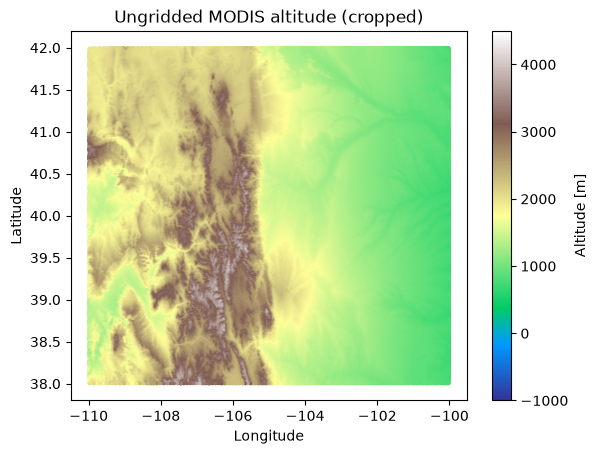

In [164]:
# --- Provided: read the MODIS geolocation data (same as modis_terrain_corrected.py) ---
import matplotlib.pyplot as plt
import numpy as np
from pyhdf.SD import SD, SDC

# NOTE on the path below: '../dat/...' is a RELATIVE path -- it means "go up one
# folder from wherever this notebook is, then into a folder called dat/". That only
# works if this notebook sits in a 'code/' folder with a sibling 'dat/' folder next to
# it (see the "Where to put this notebook" note above). If you get a
# FileNotFoundError here, this is almost always why -- check your folder layout first.
file = '../dat/MOD03.A2017233.1745.006.2017234003402.hdf'
handle = SD(file, SDC.READ)

lat = handle.select('Latitude').get()
lon = handle.select('Longitude').get()
alt = handle.select('Height').get()

# Flatten the 2D swath into a 1D list of scattered (lon, lat, alt) points
lat = np.ravel(lat)
lon = np.ravel(lon)
alt = np.ravel(alt)

# Crop to the same region we used in class. This isn't just for a tidier plot: the
# gridding loop you'll write below has to check every one of these points against the
# grid, one at a time, so fewer points means a faster loop. A full MOD03 granule covers
# a swath of roughly 1354 x 2030 pixels -- several million points -- so cropping first,
# before gridding, is what keeps that loop fast instead of something you wait on.
wesn = [-110, -100, 38, 42]   # [west, east, south, north]
flt = np.where((lon > wesn[0]) & (lon < wesn[1]) & (lat > wesn[2]) & (lat < wesn[3]))
lat = lat[flt]
lon = lon[flt]
alt = alt[flt]
n = len(alt)
print(n, 'scattered altitude points to grid')

# This is the "before" picture for this task: a scattered cloud of points, not on any
# grid. Compare it to the gridded version you'll produce at the end of Task 1.
plt.figure()
plt.scatter(lon, lat, c=alt, cmap='terrain', vmin=-1000, vmax=4500, s=2)
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Ungridded MODIS altitude (cropped)')
plt.colorbar(label='Altitude [m]')
plt.show()


In [165]:
# --- Provided: define the regular target grid (same pattern as grid_regular_annotated.py) ---
dx = dy = 0.01   # ~1 km grid spacing at this latitude -- hence "1 km" in the product name

x = np.arange(wesn[0], wesn[1], dx)   # grid-cell BOUNDARIES, west to east
y = np.arange(wesn[2], wesn[3], dy)   # grid-cell BOUNDARIES, south to north
nx = len(x) - 1
ny = len(y) - 1

xm = 0.5 * (x[:-1] + x[1:])   # grid-cell MIDPOINTS
ym = 0.5 * (y[:-1] + y[1:])

print(nx, 'x', ny, 'target grid cells')


999 x 399 target grid cells


In [166]:
# --- TODO: grid the scattered altitude data onto (nx, ny) ---
#
# You need two (nx, ny) arrays:
#   cnt -- how many scattered points landed in each grid cell
#   dat -- the SUM of the altitude values that landed in each grid cell
#          (you will divide this by cnt in the next cell to get the mean)
#
# Loop over every scattered point i in range(n) and find which grid cell (xind, yind)
# it belongs to. There are two ways to do this, and the difference is worth knowing:
#
#   Option A -- np.argmin(np.abs(xm - lon[i])), the method from grid_regular_annotated.py.
#   Works on ANY grid, even an irregular one, because it searches for the closest
#   midpoint directly. The cost: it scans the whole xm (and ym) array for every single
#   point, so it gets slower the more points you grid or the finer your grid is.
#
#   Option B -- direct index arithmetic: xind = int((lon[i] - wesn[0]) / dx). Our grid
#   IS regular (built with a constant dx, dy), so the index can be computed with one
#   division instead of a search -- much faster across a loop of thousands of points.
#   The catch: unlike argmin, it can hand you an index that's out of range (exactly nx,
#   for a point sitting right on the domain edge) -- so you still need the bounds check
#   in step 2 below either way.
#
# For a loop over this many points, Option B is the one worth using. If you're curious
# just how much faster, time both versions (wrap the loop with
# t0 = time.time() ... print(time.time() - t0), after import time) -- it's a bigger gap
# than you might expect.
#
#   1) find (xind, yind) using either method above, applied against the MIDPOINTS
#      xm, ym (not the boundaries), since we want the cell a point falls INSIDE.
#   2) check that (xind, yind) actually falls within the grid (0 <= xind < nx and
#      0 <= yind < ny) -- some MODIS points may lie right at the edge of our crop.
#   3) if it does, add 1 to cnt[xind, yind] and alt[i] to dat[xind, yind].

cnt = np.zeros((nx, ny))
dat = np.zeros((nx, ny))

# TODO: your loop here
for i in range(n):
    xind = int((lon[i] - wesn[0]) / dx)
    yind = int((lat[i] - wesn[2]) / dy)
    if ((0 <= xind < nx) & (0 <= yind < ny)):
        cnt[xind,yind] += 1
        dat[xind,yind] += alt[i]

print(cnt)
print(dat)

[[1. 1. 1. ... 0. 0. 0.]
 [0. 0. 0. ... 2. 1. 0.]
 [1. 1. 1. ... 0. 0. 1.]
 ...
 [1. 1. 1. ... 0. 1. 2.]
 [1. 1. 1. ... 1. 1. 0.]
 [1. 1. 0. ... 1. 0. 1.]]
[[1878. 1845. 1758. ...    0.    0.    0.]
 [   0.    0.    0. ... 3898. 1976.    0.]
 [1972. 1876. 1827. ...    0.    0. 1973.]
 ...
 [ 773.  772.  769. ...    0.  805. 1575.]
 [ 771.  769.  769. ...  798.  786.    0.]
 [ 765.  766.    0. ...  805.    0.  782.]]


In [167]:
# --- TODO: convert the per-cell SUM into a per-cell MEAN ---
# Only divide where cnt > 0 -- cells with no data should be left at 0 (or set to np.nan,
# your choice, as long as you say which you picked).

# TODO: your code here

for i in range(nx):
    for j in range(ny):
        val_divisor = cnt[i][j]
        val_num = dat[i][j]
        if val_divisor > 0:
            dat[i][j] = val_num/val_divisor
        else:
            dat[i][j] = np.nan

print(dat)

[[1878.  1845.  1758.  ...    nan    nan    nan]
 [   nan    nan    nan ... 1949.  1976.     nan]
 [1972.  1876.  1827.  ...    nan    nan 1973. ]
 ...
 [ 773.   772.   769.  ...    nan  805.   787.5]
 [ 771.   769.   769.  ...  798.   786.     nan]
 [ 765.   766.     nan ...  805.     nan  782. ]]


Text(0, 0.5, 'Latitude')

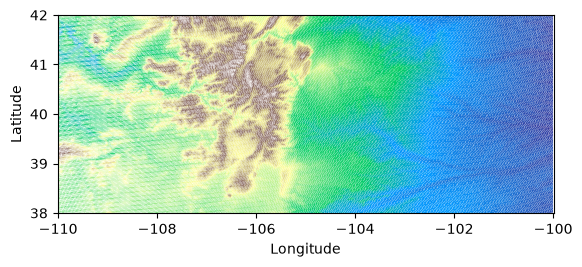

In [168]:
# --- TODO: display your gridded altitude product ---
# Use plt.imshow with cmap='terrain' and extent=wesn, the same way we displayed the
# WorldView image in grid_regular_annotated.py. Compare the result to the reference
# plot posted with this assignment -- it should look similar, but gridded instead of
# a continuous image. Don't forget axis labels and a colorbar.
# Hint: imshow expects the array as [row, col] = [y, x], so you likely need dat.T
# (transpose), the same gotcha we ran into with img[ny-1-yind, xind, 2] in class.

# TODO: your code here


plt.imshow(dat.T, cmap='terrain', extent=wesn)
plt.xlim(wesn[0] - 0.01, wesn[1] + 0.01)
plt.ylim(wesn[2] - 0.01, wesn[3] + 0.01)
plt.xlabel('Longitude')
plt.ylabel('Latitude')

*Optional thought question (not graded, but worth thinking about): why do some grid
cells in your plot have no data at all? What would you need to do differently if you
wanted every cell in your grid to be filled?*


Because some grid cells dont have a point within them. If you wanted to fill in every cell, interpolate.

## Task 2 [20] -- A Boulder temperature climatology

`weather.py` (same reader you used for HW5) also has two functions we haven't used yet:
`make_climate(start, end)`, which reads many days of Skywatch data at once, and
`plot_t2m(climate)`, which plots all of it as one time series.

**Note:** `make_climate` as written only reads data for the year 2017 (it's hardcoded as
`'2017'+mm+dd`). Below we've given you a small drop-in replacement, `make_climate_year`,
that takes the year as an argument, so you can pick whichever month/year you like for
part (b) -- data are available from 8/7/2016 onward.

### (a) Warm-up: run the provided climate functions for one month


In [169]:
# --- Provided: imports and a year-aware version of make_climate ---
# NOTE: the line below only works if weather.py is sitting in the SAME folder as this
# notebook (see the "Where to put this notebook" note at the top). If you get a
# ModuleNotFoundError: No module named 'weather', that's why -- move this notebook (or
# a copy of weather.py) so they're side by side, then try again.
from weather import WEATHER, plot_t2m
import numpy as np

def make_climate_year(year, start, end):
    """Same as weather.make_climate, but you choose the year too.
    start, end are months: 1=January ... 12=December."""
    climate = []
    for j in range(start - 1, end):
        mm = str(j + 1).zfill(2)
        for i in range(31):
            dd = str(i + 1).zfill(2)
            weatherdata = WEATHER(str(year) + mm + dd)
            if hasattr(weatherdata, 'doy'):
                climate.append(weatherdata)
    return climate


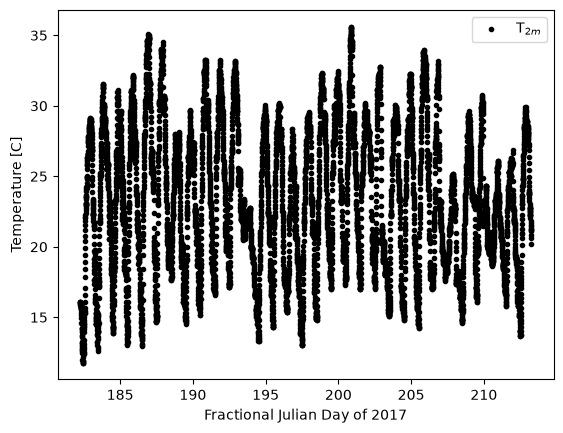

In [170]:
# --- Provided: plot one month (July 2017) using the existing plot_t2m function ---
climate = make_climate_year(2017, 7, 7)
plot_t2m(climate)


### (b) Your task: daily mean / min / max over a period of your choice

Using a `climate` list (from `make_climate_year`, for any month/year range you like --
it does not need to be July 2017), write code that:

1. Computes the **daily mean, minimum, and maximum** temperature for each day in the
   list (each entry in `climate` is one day's `WEATHER` object; its temperatures are in
   `.t2m`, and its fractional day number is in `.frc` -- use `np.nanmean`, `np.nanmin`,
   `np.nanmax` so missing-data gaps don't break your statistics).
2. Plots all three (mean, min, max) as a single time series over your chosen period,
   with a visualization that makes the daily range easy to read -- for example,
   `plt.fill_between(days, daily_min, daily_max, alpha=0.3)` to shade the min-max range,
   with the daily mean plotted as a line on top. (You're welcome to use a different
   visualization if you prefer -- just make sure mean, min, and max are all visible and
   labeled.)


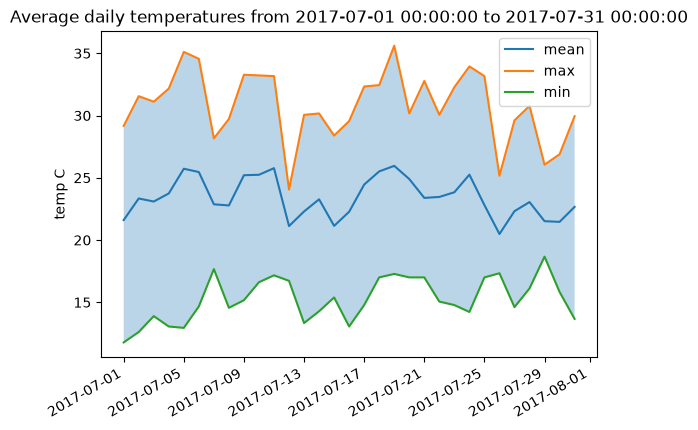

In [171]:
# TODO: your code here

import pandas as pd
climate = make_climate_year(2017, 7, 7)

daily_frc = []
days= []
daily_temp = []
daily_mean = []
daily_min = []
daily_max = []

for i in range(len(climate)):
    daily_frc.append(climate[i].frc)
    days.append(pd.to_datetime(climate[i].date, format='%Y%m%d'))
    daily_temp.append(climate[i].t2m)
    daily_mean.append(np.nanmean(climate[i].t2m))
    daily_min.append(np.nanmin(climate[i].t2m))
    daily_max.append(np.nanmax(climate[i].t2m))

fig, ax = plt.subplots()
ax.fill_between(days, daily_min, daily_max, alpha=0.3)
ax.plot(days, daily_mean, label = "mean")
ax.plot(days, daily_max, label = "max")
ax.plot(days, daily_min, label = "min")
fig.autofmt_xdate()
ax.set_ylabel("temp C")
ax.set_title(f"Average daily temperatures from {np.nanmin(days)} to {np.nanmax(days)}")
ax.legend()

## Task 3 [20] -- Taylor series

The Taylor expansion is a powerful way to represent almost any function as a series of
polynomials -- a very useful concept for scientific programming. For example, sine can
be written as:

$$\sin(x) = x - \frac{x^3}{3!} + \frac{x^5}{5!} - \frac{x^7}{7!} + \cdots$$

For the range $[0, 4\pi]$, plot $\sin(x)$, as well as its approximation using only the
first term ($x$), the first two terms, the first three terms, and so on, up to the first
10 terms. **Use a `for` loop to do this** (do not copy/paste the plotting code multiple
times). Scale the y-axis to `[-5, 5]` with `plt.ylim(-5, 5)`.

Hints:
- You can get the alternating sign with `(-1)**i` (note: *not* `(-1)**(2*i+1)`, which is
  always $-1$ and would give every term the same sign -- that was a typo in an earlier
  version of this problem).
- `math.factorial(k)` gives you $k!$.
- The $i$-th term (starting at $i=0$) is $(-1)^i \dfrac{x^{2i+1}}{(2i+1)!}$.


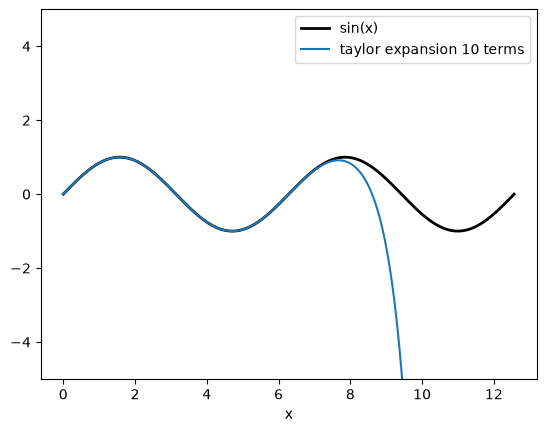

In [172]:
import math
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(0, 4 * np.pi, 500)

plt.figure()
plt.plot(x, np.sin(x), 'k-', linewidth=2, label='sin(x)')

# TODO: your for loop here, adding one more Taylor term each iteration (10 terms total)
# and plotting the running approximation after each term is added.

ysum = 0
r = 10
for i in range(r):
    y = (-1)**i * x**(2*i+1) * (math.factorial(2*i+1))**(-1)
    ysum += y
plt.plot(x, ysum, label= f'taylor expansion {r} terms')

plt.ylim(-5, 5)
plt.xlabel('x')
plt.legend()
plt.show()
